<a href="https://colab.research.google.com/github/amalasoy/Learnings-from-DSA-2/blob/main/casestudy_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [112]:
data=pd.read_csv('/content/car_age_price (1).csv')

In [113]:
data.head()

,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000


In [114]:
data.isna().sum()

,0
Year,0
Price,0


<Axes: >

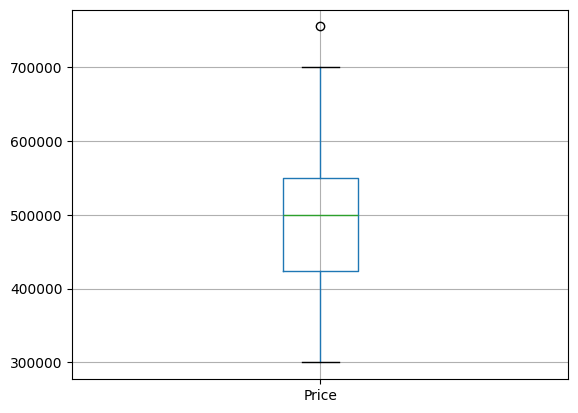

In [115]:
data.boxplot('Price')

In [116]:
data['Price'].unique()

array([465000, 755000, 700000, 350000, 425000, 575000, 509999, 500000,
       600000, 475000, 550000, 434999, 650000, 450000, 486000, 545000,
       525000, 396000, 325000, 345000, 341000, 490000, 540000, 595000,
       495000, 400000, 300000, 320000, 409999, 390000, 480000, 520000,
       640000, 375000, 420000])

<Axes: >

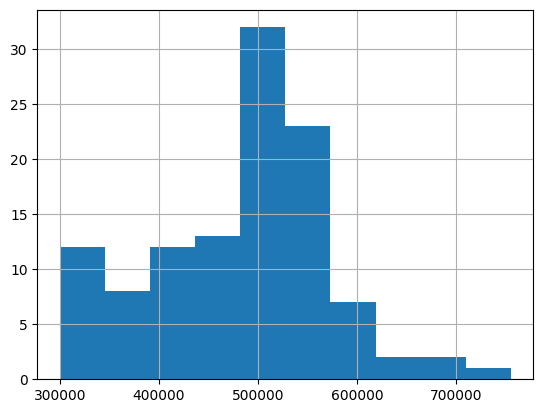

In [117]:
data['Price'].hist()

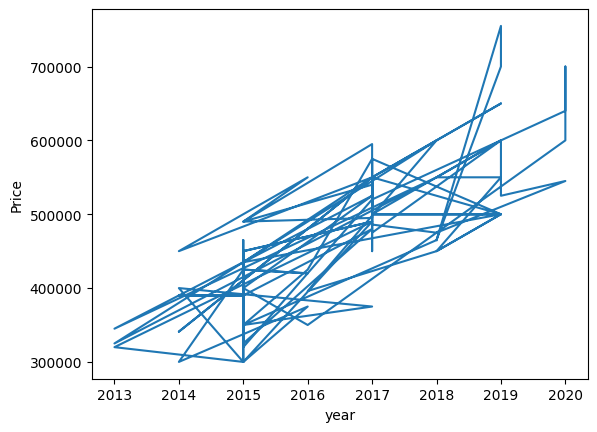

In [118]:
x = data['Year']
y=data['Price']
plt.plot(x,y)
plt.xlabel('year')
plt.ylabel('Price')
plt.show()

In [119]:
q1=np.percentile(data['Price'],25)
q2=np.percentile(data['Price'],50)
q3=np.percentile(data['Price'],75)
print(q1,q2,q3)

423750.0 500000.0 550000.0


In [120]:
IQR = q3-q1

In [121]:
low_lim = q1-IQR*1.5
upp_lim = q3+IQR*1.5
print(low_lim,upp_lim)

234375.0 739375.0


In [122]:
ind = data['Price']>upp_lim
data.loc[ind].index

Index([1], dtype='int64')

In [123]:
outlier=[]
for i in data['Price']:
  if i>upp_lim:
    outlier.append(i)

print(outlier)

[755000]


In [124]:
pd.DataFrame(data[['Price']])

,Price
0,465000
1,755000
2,700000
3,465000
4,465000
...,...
107,375000
108,300000
109,425000
110,420000


In [125]:
data['Price']= data['Price'].clip(lower = low_lim, upper= upp_lim)

<Axes: >

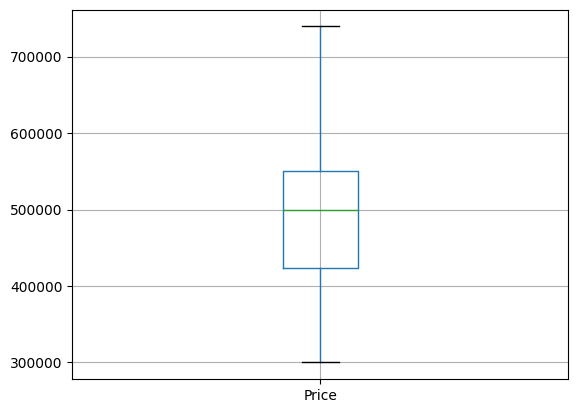

In [126]:
data.boxplot('Price')

In [127]:
x= data.drop('Price', axis=1)
y=data['Price']

In [128]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [129]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [130]:
lr.fit(x_train,y_train)

LinearRegression()

In [131]:
y_pred = lr.predict(x_test)

In [132]:
y_pred

array([600170.13478352, 505305.89519151, 552738.01498751, 552738.01498751,
       552738.01498751, 410441.6555995 , 505305.89519151, 552738.01498751,
       600170.13478352, 600170.13478352, 315577.4160075 , 505305.89519151,
       410441.6555995 , 647602.25457953, 552738.01498751, 600170.13478352,
       315577.4160075 , 410441.6555995 , 505305.89519151, 505305.89519151,
       505305.89519151, 505305.89519151, 505305.89519151])

In [133]:
y_pred = pd.DataFrame(y_pred)

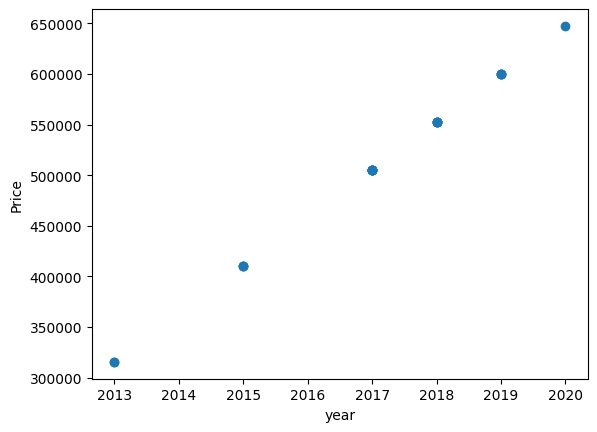

In [134]:
x = x_test['Year']
y = y_pred
plt.scatter(x,y)
plt.xlabel('year')
plt.ylabel('Price')
plt.show()

In [135]:
y_pred_2022 = lr.predict(data[['Year']]==2022)
print("prediction of second hand car prize in 2022 is :",y_pred_2022)

prediction of second hand car prize in 2022 is : [-95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95165279.73334719 -95165279.73334719
 -95165279.73334719 -95

In [136]:
from sklearn.metrics import r2_score, mean_squared_error

In [137]:
msr1= mean_squared_error(y_test,y_pred)
msr1

4296980485.322585

In [138]:

r2_score_val1 = r2_score(y_test, y_pred)


In [139]:
r2_score_val1

0.3719669899056065

In [140]:
from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()

In [141]:
x1 = std_scaler.fit_transform(pd.DataFrame(x))

In [142]:

x1= pd.DataFrame(x1)

In [143]:
x1_train, x1_test, y_train, y_test = train_test_split(x1, y, test_size=0.2, random_state=42)
lr2 = lr.fit(x1_train, y_train)

In [144]:
y_pred2 = lr2.predict(x1_test)

In [145]:
y_pred2

array([[600170.13478351],
       [600170.13478351],
       [600170.13478351],
       [600170.13478351],
       [410441.6555995 ]])

In [146]:
msr2 = mean_squared_error(y_test,y_pred2)
msr2

3.5307721373348255e-17

In [147]:
r2_score_val2 = r2_score(y_test, y_pred2)

In [148]:
r2_score_val2

1.0

In [149]:
from sklearn.linear_model import Lasso

In [151]:
lasso_model = Lasso(alpha=0.1)
lasso_model = lasso_model.fit(x1_train, y_train)

In [156]:
y_pred_lasso = lasso_model.predict(x1_test)

In [157]:
y_pred_lasso

array([600169.99985131, 600169.99985131, 600169.99985131, 600169.99985131,
       410441.76354527])

In [160]:
msr_lasso = mean_squared_error(y_test,y_pred_lasso)
msr_lasso

0.01689581847862962

In [161]:
r2_score_lasso = r2_score(y_test, y_pred_lasso)
r2_score_lasso

0.9999999999970665

From the above analysis, it is clear that lasso model using scaled data is performing much better with less mean squared error value and better r2 score value. However, the y prediction values of the non-scaled data shows a linear relation.